In [2]:
#Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import missingno as msno
from scipy.stats import mannwhitneyu,chi2_contingency

In [3]:
# Set up path to the data file and read it into a DataFrame
notebook_path = Path.cwd()
project_path = notebook_path.parent
data_path = project_path / "data" / "processed" / "raw_master_table.csv"
df = pd.read_csv(data_path)

# Fixing data types (seqn to be int (there is no NULL), categorical columns to be 'Int64' (so it doesn't convert to float again after a NULL))
df['seqn'] = df['seqn'].astype(int)

cat_cols=[
    "sex",
    "military_service",
    "education",
    "firearm_and_protection",
    "firearm_exposure_level",
    "loud_noise",
    "very_loud_noise",
    "heart_disease",
    "heart_attack",
    "stroke",
    "cancer",
    "diabetes",
    "hl_presence",
    "hl_severity",
]
df[cat_cols]= df[cat_cols].astype('Int64')

#Checking the NULL data percentage in each column
missing_pct = df.isnull().mean().sort_values(ascending=False) * 100
print(missing_pct)

very_loud_noise           67.138547
lead                      52.100255
cadmium                   52.100255
income_poverty_ratio       8.888373
blood_pressure             1.972615
bmi                        0.580181
firearm_exposure_level     0.533767
heart_disease              0.255280
firearm_and_protection     0.139243
loud_noise                 0.092829
cancer                     0.069622
stroke                     0.046414
heart_attack               0.046414
diabetes                   0.046414
education                  0.000000
age                        0.000000
sex                        0.000000
seqn                       0.000000
military_service           0.000000
hl_presence                0.000000
hl_severity                0.000000
dtype: float64


After checking the codebook, I realized very_loud_noise was NULL for every person who answered "no" to loud_noise question. So in the imputation phase, 
we can choose "no" for this column when very_oud_noise value is NULL and its corresponding loud_noise is "no". 
Because the NULL percentage is very high, it will affect our eda visulizations on the data distribution, so I will do this imputation now (instead of after EDA in the cleaning phase).

In [4]:
df.loc[(df['loud_noise'] == 1) & (df['very_loud_noise'].isnull()), 'very_loud_noise'] = 1

<Axes: >

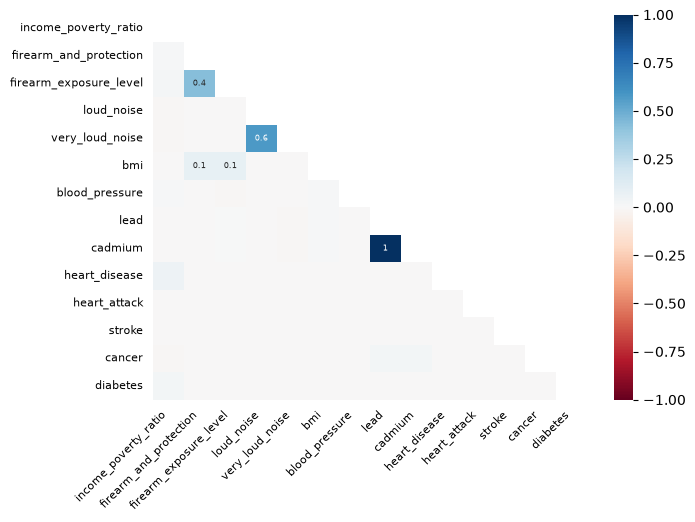

In [5]:
#Correlation for NULL 
msno.heatmap(df,figsize=(7, 5), fontsize= 8)

The figure shows the correlation between features on NULL values. Based on the codebook and this figure, Lead and Cadmium used a same blood sample test
and its presence was randomized on nearly half of the subjects, so they are both NULL at the same time. 

As for 0.6 and 0.4 correlations, both 2 groups of questions (firearm usage and noise in work) are asked within the same section, so a person who skips the first one is likely to skip the second one.

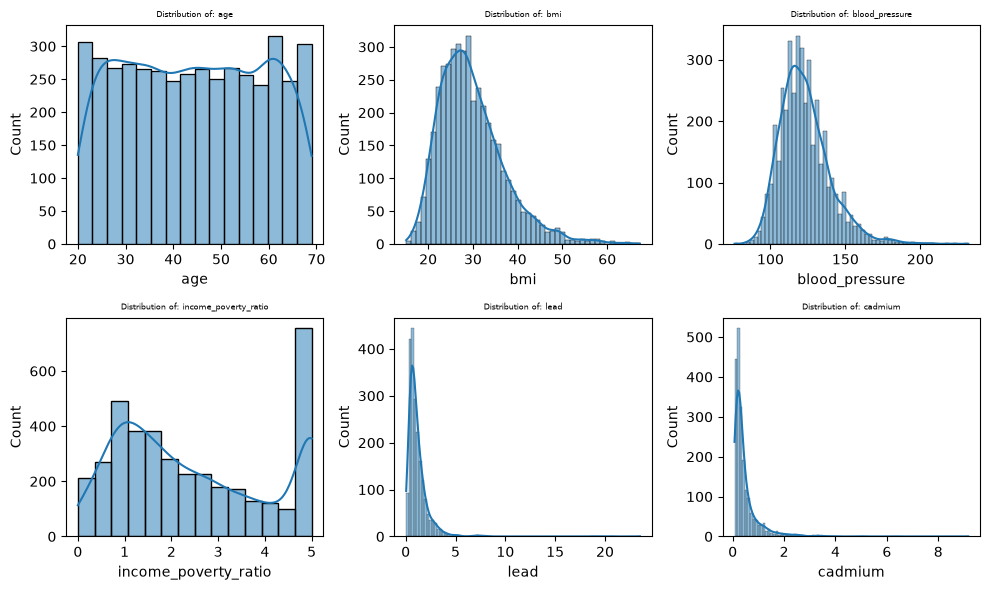

In [6]:
# UNIVARIATE EDA
# Distribution on continuous features
continuous_features = ['age','bmi', 'blood_pressure', 'income_poverty_ratio', 'lead', 'cadmium']
fig, axes = plt.subplots (nrows= 2, ncols= 3, figsize= (10, 6))
axes = axes.flatten()

for i, col in enumerate(continuous_features):
    sns.histplot(data= df, x=col, kde= True, ax= axes[i])
    axes[i].set_title(f'Distribution of: {col}', fontsize = 6)


plt.tight_layout()
plt.show()

Lead & Cadmium : They are heavily right skewed, so we use median instead of mean for imputation as it is more close to the majority.

Income poverty ratio: There is a spike in column 5. The reason is that all incomes higher than level 5 are labeled as 5 by NHANES. I will use Median for this as well.

BMI & Blood Pressure: Pretty normal, I will use Median for imputation.

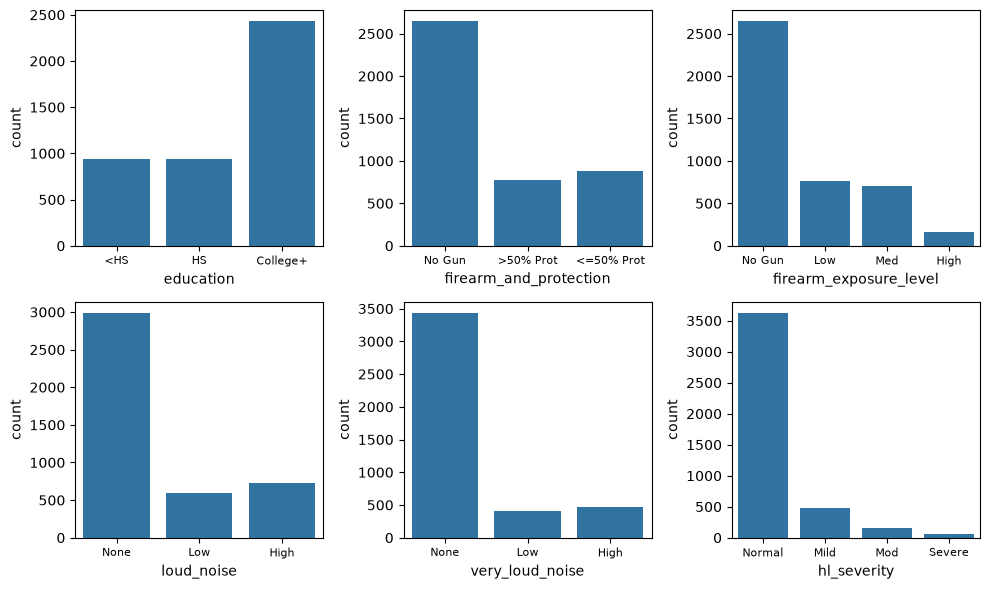

In [7]:
# Distribution on Ordinal Features
ordinal_features= ['education', 'firearm_and_protection', 'firearm_exposure_level', 'loud_noise', 'very_loud_noise', 'hl_severity']
labels = {
    'education': ['<HS', 'HS', 'College+'],
    'firearm_and_protection': ['No Gun', '>50% Prot', '<=50% Prot'],
    'firearm_exposure_level': ['No Gun', 'Low', 'Med', 'High'],
    'loud_noise': ['None', 'Low', 'High'],
    'very_loud_noise': ['None', 'Low', 'High'],
    'hl_severity': ['Normal', 'Mild', 'Mod', 'Severe']
}

fig, axes = plt.subplots (nrows= 2, ncols= 3, figsize= (10, 6))
axes = axes.flatten()

for i, col in enumerate(ordinal_features):
    sns.countplot(data= df, x= col, ax= axes[i])
    axes[i].set_xticks(range(len(labels[col])))
    axes[i].set_xticklabels(labels[col], fontsize = 8)

plt.tight_layout()
plt.show()

Before plotting the binary features, I realized I coded the values in (1, 2). I am going to map them first to (0, 1) right now as it makes it easier to use functions like mean() on them. 

In [8]:
#Remapping to (0, 1), but in a way so when the code block is run more than once, we are not going to have 0 for every row.
binary_cols = ['sex', 'military_service', 'heart_disease', 'heart_attack', 'stroke', 'cancer', 'diabetes']
for col in binary_cols:
    if (df[col] == 2).any():
        df[col] = df[col].replace({1: 0, 2: 1})

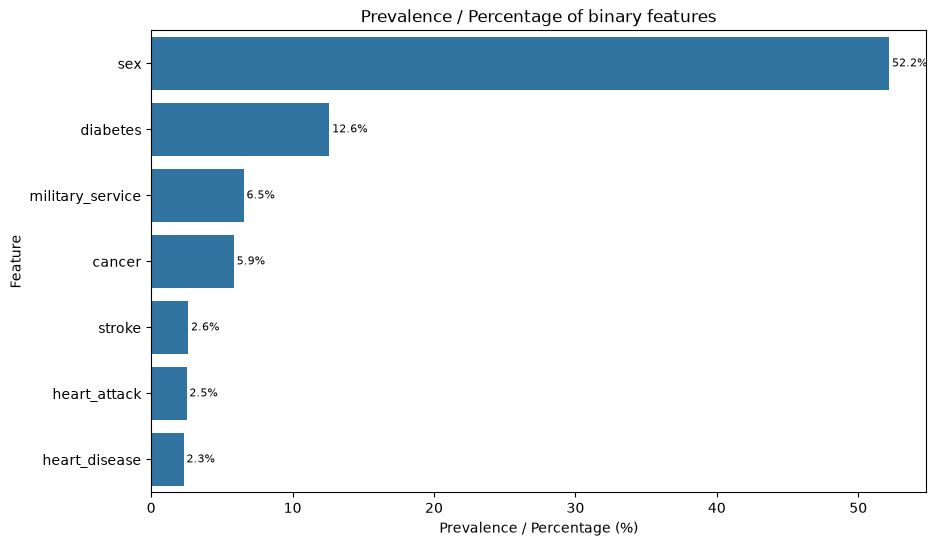

In [9]:
# Prevalence / Percentage of binary features
prevalence = df[binary_cols].mean().sort_values(ascending=False) * 100
plt.figure(figsize=(10, 6))
ax= sns.barplot(x=prevalence.values, y=prevalence.index, orient='h')
ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=2, fontsize= 8)
plt.xlabel('Prevalence / Percentage (%)')
plt.ylabel('Feature')
plt.title('Prevalence / Percentage of binary features')
plt.show()

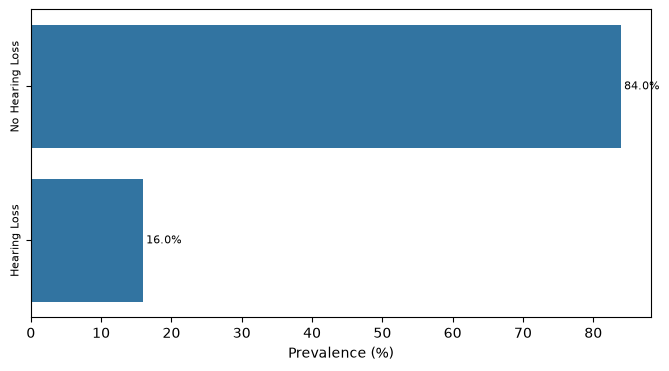

In [10]:
# Prevalence of our target variable Hearing loss
pct = df['hl_presence'].value_counts(normalize= True) * 100
plt.figure(figsize=(8, 4))
ax= sns.barplot(x= pct.values, y= ['No Hearing Loss', 'Hearing Loss'],  orient='h')
plt.yticks(rotation=90, fontsize= 8, va='center')
ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=2, fontsize= 8)
plt.xlabel('Prevalence (%)')
plt.show()

Based on the obvious imbalance in our target variable, we are going to use weighted class for training our models (in addition to the regular parameter tuning). Then on the validation set, we will use PR-AUC to compare our different models to see which one performs best (as it is a much better choice for imbalanced data than ROC-AUC as it is not affected by a large number of True Negatives). At the end we use F2 score (as it is much more costly to miss someone in risk of hearing loss than just a false alarm) to find the threshold that maximizes the metric. We will test the final model on our test set.

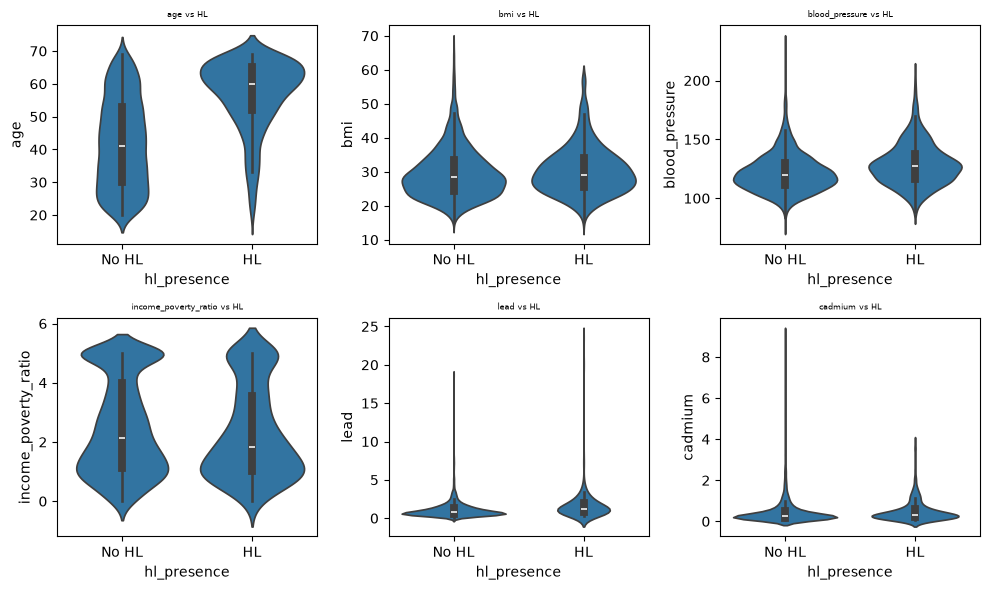

                feature  median (no HL)  IQR (no HL)  Median (HL)  IQR (HL)  \
0                   age           41.00       23.000       60.000     13.00   
1                   bmi           28.40        9.200       29.200      8.65   
2        blood_pressure          120.00       19.000      127.000     22.00   
3  income_poverty_ratio            2.12        2.895        1.845      2.53   
4                  lead            0.82        0.810        1.190      1.15   
5               cadmium            0.28        0.330        0.320      0.39   

   Skewness  Rank-Biserial  p-value  
0     0.011          0.598    0.000  
1     1.097          0.090    0.000  
2     1.089          0.252    0.000  
3     0.376         -0.077    0.002  
4     8.174          0.302    0.000  
5     4.859          0.115    0.001  


In [11]:
# BIVARIATE EDA
# Continous features against HL
fig, axes = plt.subplots (nrows= 2, ncols= 3, figsize= (10, 6))
axes = axes.flatten()

for i, col in enumerate(continuous_features):
    sns.violinplot(data= df, x='hl_presence', y= col, ax= axes[i])
    axes[i].set_title(f'{col} vs HL', fontsize = 6)
    axes[i].set_xticks(range(0,2))
    axes[i].set_xticklabels(['No HL', 'HL'])
    
plt.tight_layout()
plt.show()

# Stats
records =[]
for col in continuous_features:
    g0 = df.loc[df['hl_presence'] == 0, col].dropna()
    g1 = df.loc[df['hl_presence'] == 1, col].dropna()

    # As most columns are not normally distributed, we use Mannwhitney
    stat, p_val = mannwhitneyu(g0,g1)

    # Due to the large size of the dataset, even very little differences can look statistically significant with P value, but they 
    # may have not any predictive value. Because of that, we also calculate Rank-Biserial correlation. It's a number between (-1, 1)
    # and the more it's closer to 0, it's more statistically insignificant.

    r_rb = 1 - (2 * stat) / (len(g0) * len(g1))
    records.append({
        'feature': col,
        'median (no HL)': g0.median(),
        'IQR (no HL)': g0.quantile(0.75) - g0.quantile(0.25),
        'Median (HL)': g1.median(),
        'IQR (HL)': g1.quantile(0.75) - g1.quantile(0.25),
        'Skewness': df[col].skew(),
        'Rank-Biserial': r_rb,
        'p-value': p_val
    })
summary_stat = pd.DataFrame(records).round(3)
print(summary_stat)

AGE: This is our strongest predictor, which is caused by Presbycusis (Hearing loss due to age)

BMI: Even though we have a <0.05 p value, RankBiserial factor is at 0.09 which is very minimal and shows there is nearly no effect caused by BMI on presence of HL.

BLOOD PRESSURE: Both p value and RankBiserial show strong prediction power for our model. In the next section you can see the correlation matrix for continous data. We have a slight (0.38) correlation between BP and AGE which is not big enough to worry about multicollinearity (even if it was multicollinearity, we are working toward a prediction model. If I were going to interpret the weights and model outputs as clinical findings, then we should be worried about it).

INCOME POVERTY RATIO: Similar to BMI, shows no real meaningfull prediction power for our model even with a significant p value. The spike in level 5 is due to NHANES system that classifies all income to poverty ratios higher than level 5 to just to 5.

LEAD: It shows semi strong prediction power but it is heavily skewed (8.1). In the training section we will use a Log Transform (log(1+x)) to fix this issue. (Because the outliers will dominate loss functions in Linear and distance based models and also dominate the scaling with large mean and sd)

CADMIUM: Simlar to BMI and INCOME POVERTY RATIO, has minimal predictive power. Based on my research, lead values up to 100–150 µg/dL and cadmium values up to 20–50 µg/L can be observed in some cases of severe exposure to these materials, so we can safely assume these outliers were not an entry error.

<Axes: >

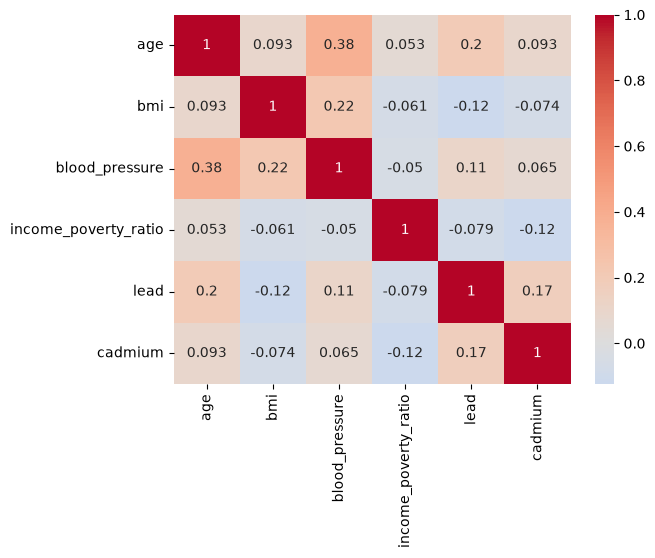

In [12]:
# Correlation matrix for continous features
corr = df[continuous_features].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0)

The strongest correlations include:

AGE/BP (0.38): Which is normal given the older adults tend to have stiffer arteries. It is not significant enough to worry about multicollinearity.

BMI/BLOOD PRESSURE (0.22): Pretty normal observation and still not strong enough for multicollinearity (I may even decide to drop BMI in the training phase as it has minimal predictive power)

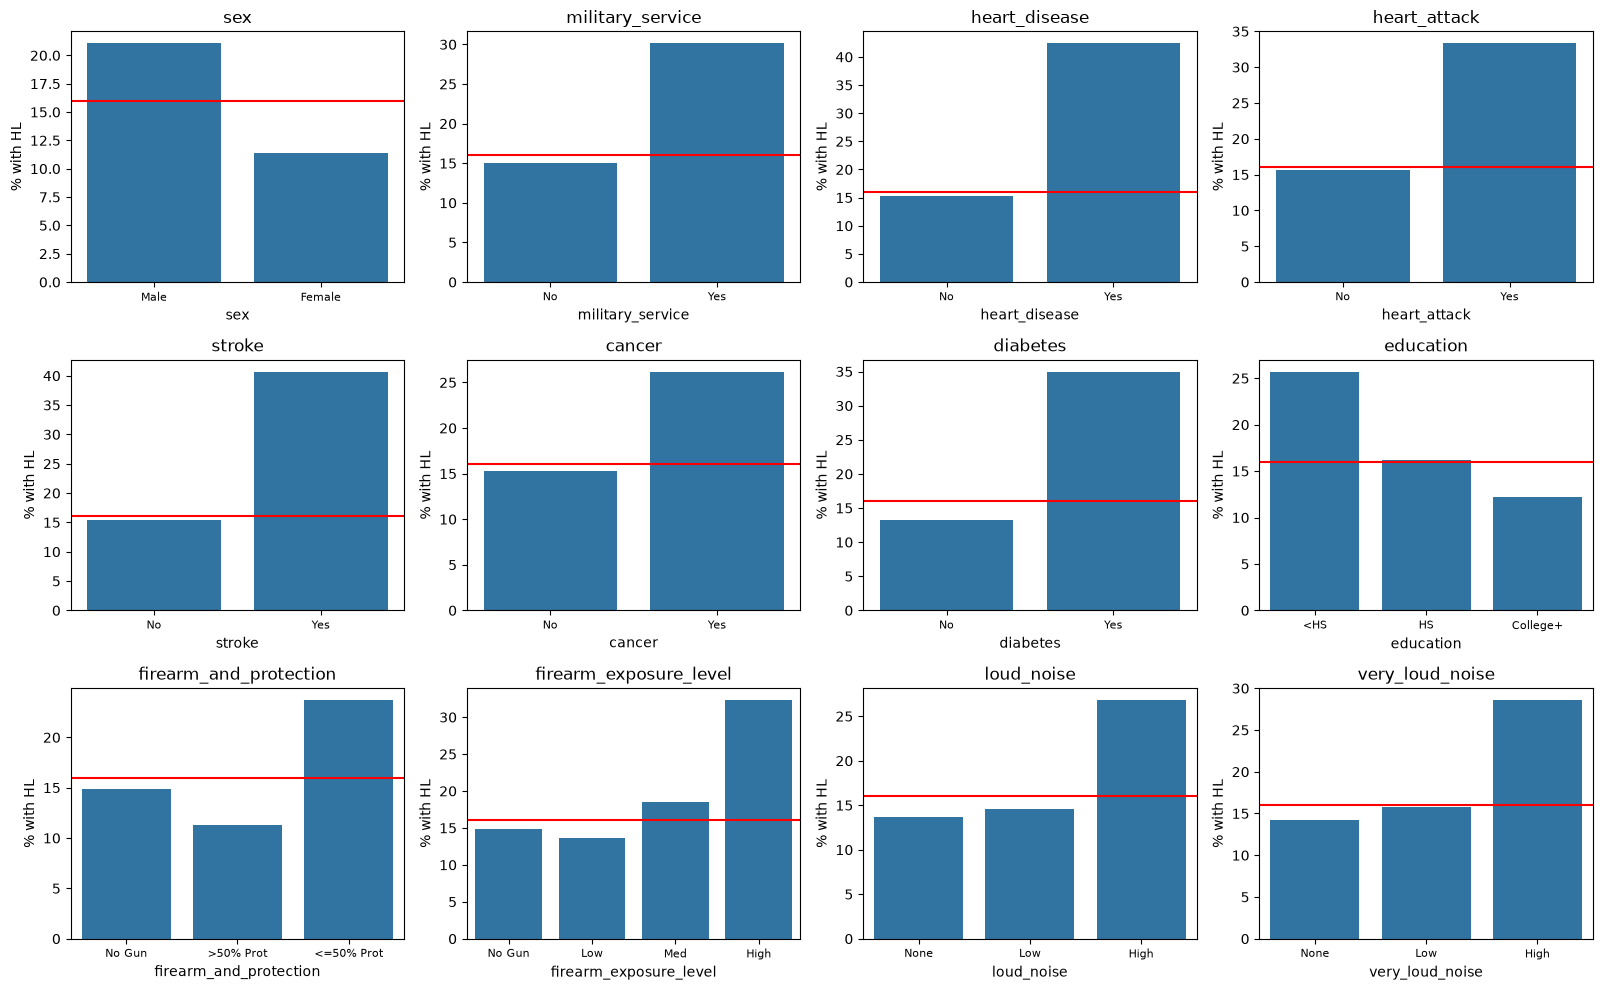

In [13]:
# Categorical features against HL
# Removing HL_Severity from ordinal features
# Without an if, we would encounter an error if the code block is run more than once.
if 'hl_severity' in ordinal_features: 
    ordinal_features.remove('hl_severity')


#Plots
labels = {
    'education': ['<HS', 'HS', 'College+'],
    'firearm_and_protection': ['No Gun', '>50% Prot', '<=50% Prot'],
    'firearm_exposure_level': ['No Gun', 'Low', 'Med', 'High'],
    'loud_noise': ['None', 'Low', 'High'],
    'very_loud_noise': ['None', 'Low', 'High'],
    'hl_severity': ['Normal', 'Mild', 'Mod', 'Severe'],
    'sex': ['Male', 'Female'],
    'military_service': ['No', 'Yes'],
    'heart_disease': ['No', 'Yes'],
    'heart_attack': ['No', 'Yes'],
    'stroke': ['No', 'Yes'],
    'cancer': ['No', 'Yes'],
    'diabetes': ['No', 'Yes'],
    'hl_presence': ['No Hearing Loss', 'Hearing Loss'],
}

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes= axes.flatten()

for i,col in enumerate(binary_cols + ordinal_features):
    prop= df.groupby(col)['hl_presence'].mean() * 100
    sns.barplot(x= prop.index, y= prop.values, ax= axes[i])
    axes[i].set_title(col)
    axes[i].set_ylabel('% with HL')
    axes[i].axhline(df['hl_presence'].mean()*100, color= 'red')
    axes[i].set_xticks(range(len(labels[col])))
    axes[i].set_xticklabels(labels[col], fontsize = 8)

plt.tight_layout()
plt.show()

In [14]:
# Statistical Test
# We Will use Cramer's V alongside ChiSquare to make sure if there is any relationship between categorical features against HL, 
# it is not affected by the size of the sample (similar to Rank Biserial that we used for continous features). 
# < 0.1 (none), 0.1 - 0.3 (weak), 0.3 - 0.5 (moderate), > 0.5 (strong)

def cramers_v(confusion_matrix):
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    r, k = confusion_matrix.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

records = []
for col in ordinal_features + binary_cols:
    ct = pd.crosstab(df[col], df['hl_presence'])
    chi2, p, dof, expected = chi2_contingency(ct)
    v = cramers_v(ct)
    records.append({
        "feature": col,
        "p_value": round(p, 5),
        "cramers_v": v
    })
    records_df = pd.DataFrame(records).sort_values('cramers_v', ascending= False)

print(records_df)

                   feature  p_value  cramers_v
11                diabetes  0.00000   0.195485
0                education  0.00000   0.146408
3               loud_noise  0.00000   0.132912
5                      sex  0.00000   0.131288
4          very_loud_noise  0.00000   0.121504
1   firearm_and_protection  0.00000   0.112446
7            heart_disease  0.00000   0.108669
9                   stroke  0.00000   0.108666
6         military_service  0.00000   0.100673
2   firearm_exposure_level  0.00000   0.099480
8             heart_attack  0.00000   0.073674
10                  cancer  0.00001   0.068144


In [15]:
# sex-stratified crosstab check 
for col in ['loud_noise', 'very_loud_noise', 'firearm_and_protection', 'firearm_exposure_level', 'military_service']:
    print(round(pd.crosstab(df['sex'], df[col], normalize = 'columns')*100, 2))

loud_noise      1     2      3
sex                           
0           38.92  61.1  73.31
1           61.08  38.9  26.69
very_loud_noise      1      2      3
sex                                 
0                41.62  65.93  76.91
1                58.38  34.07  23.09
firearm_and_protection      1      2      3
sex                                        
0                       35.46  60.31  73.77
1                       64.54  39.69  26.23
firearm_exposure_level      1      2      3      4
sex                                               
0                       35.46  49.41  81.24  92.81
1                       64.54  50.59  18.76   7.19
military_service      0      1
sex                           
0                 44.92  89.01
1                 55.08  10.99


All 12 categorical features are statistically significant relative to hearing loss with a very small p value, but when we take into account the sample size with cramer's v, all of them fall under 0.2 which shows each one of them are weak predictors by themselves.

Notable features:

Diabetes (v=0.195) and education (v=0.146) rank above every noise exposure feature. Diabetes could lead to microvascular damage to the cochlea but I believe its confounding effect with age also plays an important role here. Education's association, I believe, mostly reflects age and job risks that come with those levels of education.

Sex (V=0.131) is a candidate confound for the noise/firearm/military exposure features, since these activities are mostly done by men (you can see that in the crosstab, for example 89% of people who have worked in the military are men which suggests some of its association may run through sex rather than being independent).

We are not computing a full pairwise correlation grid across all features at this stage: the mixed data types (continuous, binary, ordinal) would require three different correlation measures with different scales and most feature pairs have no reason to correlate. Instead, one complete multicollinearity check will be done via VIF on the final encoded feature matrix before modeling.

In [ ]:
# Trnasferring the df file to be cleaned in the cleaning notebook
# The dataframe that we have here has already been fixed for some of the issues which are:
# 1- Corrected dtypes
# 2- 'very_loud_noise' structural recode
# 3- relabeling binary features to 0/1
# These three corrections are treated as part of EDA rather than cleaning, since each was necessary for the EDA results shown above to 
# be meaningful (for example, the `very_loud_noise` missingness figures and plots would be wrong without the recode). The cleaning notebook picks 
# up directly from this file rather than repeating these steps.


# We will use parquet instead of CSV here. Because CSV will drop Int64 nullable dtype on reloading. (we are preserving the dtype fix)
output_path = project_path / "data" / "processed" / "post_eda_master_table.parquet"
df.to_parquet(output_path, index= False)
